In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import os
import joblib

In [2]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
from src import load_and_save_data, import_data, get_project_root

First of all, we should load our data, using the function that we've just created, into a training set and a test set. I will use a 70/30 split (70% of the instances will be used for training and the remaining 30% ones will be used

In [3]:
load_and_save_data(test_size=0.3)

Saving X_train.csv...
Saving X_test.csv...
Saving y_train.csv...
Saving y_test.csv...
All datasets are been successfully saved to data/processed!


In [4]:
X_train, X_test, y_train, y_test = import_data()

In [5]:
X_train.shape

(560, 20531)

In [6]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 560 entries, sample_523 to sample_102
Columns: 20531 entries, ?|100130426 to tAKR|389932
dtypes: float64(20531)
memory usage: 87.7 MB


In [7]:
X_train.describe()

,?|100130426,?|100133144,?|100134869,?|10357,?|10431,?|136542,?|155060,?|26823,?|280660,?|317712,...,ZXDA|7789,ZXDB|158586,ZXDC|79364,ZYG11A|440590,ZYG11B|79699,ZYX|7791,ZZEF1|23140,ZZZ3|26009,psiTPTE22|387590,tAKR|389932
count,560.000000,560.000000,560.000000,560.000000,560.000000,560.0,560.000000,560.000000,560.000000,560.000000,...,560.000000,560.000000,560.000000,560.000000,560.000000,560.000000,560.000000,560.000000,560.000000,560.000000
mean,0.017927,2.972548,3.054010,6.686648,9.825460,0.0,7.381775,0.511171,0.014240,0.013226,...,5.894704,8.772735,10.055050,4.813159,9.740359,11.735400,10.144615,9.592009,5.530686,0.102262
std,0.097983,1.182550,1.049161,0.618566,0.505932,0.0,1.132364,0.514772,0.124430,0.199990,...,0.756564,0.616297,0.372186,2.385671,0.527733,0.659811,0.602581,0.555983,2.076948,0.379097
min,0.000000,0.000000,0.000000,5.083098,8.435999,0.0,3.930747,0.000000,0.000000,0.000000,...,2.853517,6.678368,8.669456,0.000000,7.974942,9.261989,7.530141,7.954417,0.593975,0.000000
25%,0.000000,2.289068,2.391066,6.279821,9.486881,0.0,6.624605,0.000000,0.000000,0.000000,...,5.469415,8.397301,9.812086,3.114893,9.399748,11.315482,9.800605,9.266748,4.151340,0.000000
50%,0.000000,3.097088,3.032788,6.635434,9.811843,0.0,7.454084,0.449007,0.000000,0.000000,...,5.971545,8.790008,10.081044,5.430566,9.795072,11.733893,10.183281,9.564609,5.198346,0.000000
75%,0.000000,3.837253,3.698359,7.027215,10.143715,0.0,8.117719,0.804424,0.000000,0.000000,...,6.418616,9.157158,10.284161,6.599984,10.076378,12.156272,10.585547,9.900044,6.806610,0.000000
max,0.818932,5.803979,6.063484,8.436861,11.355621,0.0,10.696255,2.779008,1.554834,4.067604,...,7.771054,11.105431,11.318243,9.139459,11.811632,13.715361,11.675653,12.813320,11.205836,5.254133


In [8]:
X_train.isnull().sum().array.sum()

np.int64(0)

Our train set has a shape of (560, 20531) and fortunately, it doesn't contain any null values! The only problem that we have is represented by the number of features (n). In fact, as you can see n >> m (where m is the number of instances) so our main goal now should be to perform dimensioanlity reduction. 

Before performing any domensionality reduction algorithms it can be useful to plot our dataset in a 2 dimensional space

In [9]:
from sklearn.manifold import TSNE

def transform_tsne(data, n_components):
    tsne = TSNE(n_components=2, random_state=42, n_jobs=-1)
    data_tnse = tsne.fit_transform(data)
    return data_tnse

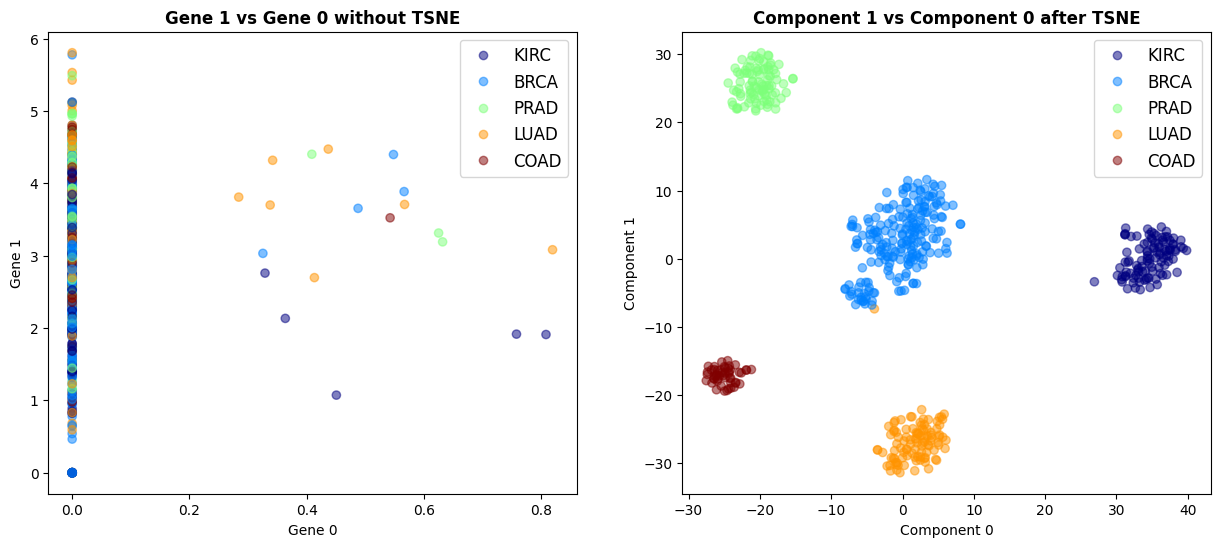

In [10]:
categories = {
    'KIRC': 0, 
    'BRCA': 1, 
    'PRAD': 2, 
    'LUAD': 3, 
    'COAD': 4
}

labels = y_train.map(categories)
class_names = y_train.unique()

X_train_tsne = transform_tsne(X_train, 2)

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

scatter0 = axs[0].scatter(X_train[X_train.columns[0]], X_train[X_train.columns[1]], 
                         c=labels, cmap="jet", alpha=0.5, )
handles0 = scatter0.legend_elements()[0]
axs[0].set_title("Gene 1 vs Gene 0 without TSNE", weight="bold")
axs[0].set_xlabel("Gene 0")
axs[0].set_ylabel("Gene 1")
axs[0].legend(handles0, class_names, loc="upper right", fontsize="large")


scatter1 = axs[1].scatter(X_train_tsne[:, 0], X_train_tsne[:, 1],
               c=labels, cmap="jet", alpha=0.5)
handles1 = scatter1.legend_elements()[0]
axs[1].set_title("Component 1 vs Component 0 after TSNE", weight="bold")
axs[1].set_xlabel("Component 0")
axs[1].set_ylabel("Component 1")
plt.legend(handles1, class_names, loc="upper right", fontsize="large")

plot_path = os.path.join(get_project_root(), "reports", "figures", "tsne_plot")
plt.savefig(plot_path)
               
plt.show()

As we can see in the second plot TSNE has done a pretty good job in clustering cancer types. Now let's try to use a pca algorithm (to see if there is a linear relationships within the data) and train a model the reduces dataset (see "notebooks/02_model_training_and_eval.ipynb")